# Lab 11: Government Data APIs

*INFO 4617/5617 · Week 11 · Chapter 11, [Government Data APIs](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html)*

This week every class is live coding: one lab in three parts, one a day. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in. After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it.

We'll use four public APIs, and each one shows an idea that holds for APIs in general:
- **Part 1, Monday:** the **Census Bureau**, and *what can I ask for?*;
- **Part 2, Wednesday:** **FRED**, the Federal Reserve Bank of St. Louis's data service, and *let the server compute*; then the **Energy Information Administration (EIA)**, and *let the server filter*;
- **Part 3, Friday:** **Congress.gov**, and *follow the links*; then a join of two of the APIs.

Along the way, short ⏱ microsprints ask you to change one thing, alone or in pairs, and share what you find.

**Before class:** open this notebook in the `webdata` environment (chapter 1), and have your email address ready for the User-Agent. Request four free keys and set them as environment variables before you start Jupyter. The chapter's ["Setting Environment Variables"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#setting-environment-variables) shows two ways; the simpler for this course stores them with the `webdata` environment, one line per key in a terminal (on Windows, the Anaconda Prompt): `conda env config vars set CENSUS_KEY="your-census-key" -n webdata`. The *Missing Manual*'s [Chapter 34](https://cuinfoscience.github.io/INFO-Missing-Manual/chapters/secrets.html#setting-environment-variables-in-your-shell) explains both.
- `CENSUS_KEY`, from the [Census Bureau](https://api.census.gov/data/key_signup.html), for Monday; click the activation link in its email before you use it;
- `FRED_KEY`, from [FRED](https://fred.stlouisfed.org/docs/api/api_key.html), and `EIA_KEY`, from the [EIA](https://www.eia.gov/opendata/register.php), for Wednesday;
- `DATAGOV_KEY`, from [api.data.gov](https://api.data.gov/signup/), for Friday's Congress.gov.

Each part reads only the keys it needs.

On Wednesday and Friday, run every cell above where we stopped (**Run → Run All Above Selected Cell**), or start at that day's setup step.

> **Instructor key.** Parts 1 and 2 were run live on 2026-10-25 with `labs/tools/run_key.py`, and every one of their cells ran. They follow the textbook at commit `8998974`, after chapter 11's second revision (textbook #290). Part 1 uses the 2020–2024 American Community Survey five-year estimates, so a rerun gives the same numbers; Step 2's list of geographies could change only with a new dataset. (The 2018–2022 estimates the first version of Part 1 used gave different numbers: 72 places without an income estimate rather than 83, and Campo had none.) Part 2's requests have fixed end dates, but FRED and the EIA revise recent values: the EIA's 2025 prices and generation are preliminary, and its total of 9,289 monthly rows will grow if it adds a source. Part 2's code is the chapter's, without its `timeout`, `raise_for_status()`, and `fred_get()`; Step 14's given loop adds a one-second pause between pages. Part 3 (Congress.gov, then a join) isn't written yet: it is added, and run, before Friday.

# Part 1 — Monday: the Census, and what can I ask for?

Every API answers only the questions it was built for, in its own words. Before we can ask the Census Bureau anything, we have to find out what it can tell us (its *variables*) and about what (its *geographies*). The Census API answers both questions itself, in catalogs we can request like any other data. Finding out what an API offers, from the API, is called *discovery*.

## Step 0 — Set up, and keep the key out of the notebook (5 minutes)

An API key identifies you, counts your requests, and is yours alone. A key typed into a notebook travels with the notebook: into a GitHub repository, a class submission, a classmate's laptop. So read the key from an environment variable, as the chapter's ["API Key Management"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#api-key-management) section does. If you haven't set it yet, the chapter's ["Setting Environment Variables"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#setting-environment-variables) shows how: Jupyter sees only the variables set before it started, so set the key, then restart Jupyter. The chapter's setup cell prints whether each of its four keys is set; [`os.environ["NAME"]`](https://docs.python.org/3/library/os.html#os.environ) goes a step further in one line, since a missing key raises a `KeyError` that names it. (The chapter also shows a second way, a `.gitignore`d `api_keys.json` file.) Today we need only `CENSUS_KEY`. Define the User-Agent too: these APIs ask for a key, but every request still says who sent it, in the book's form.

In [1]:
# Import os, requests, pandas (as pd), and matplotlib.pyplot (as plt)
# Define HEADERS, whose "User-Agent" is "WebDataScience/1.0 (your-email@colorado.edu)", with your email
# Read CENSUS_KEY into census_key with os.environ[...]; never print the key
import os
import requests
import pandas as pd
import matplotlib.pyplot as plt

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
census_key = os.environ["CENSUS_KEY"]
print("Census key found")

Census key found


<details>
<summary>💬 Discuss</summary>

- In week 10 we told Wikipedia who we are with a User-Agent. The Census Bureau also asks for a key: what can a key do that a User-Agent can't?
- Where could a key typed into this notebook end up: a commit, a screenshot, a shared notebook? The Census Bureau takes the key in the URL, so `response.url` contains it too. Which of those could you take back?
- If `CENSUS_KEY` isn't set, what does this cell do? Why is that better than finding out at the first request?

</details>

## Step 1 — What can I ask about? The variable catalog (7 minutes)

The [American Community Survey](https://www.census.gov/data/developers/data-sets/acs-5year.html)'s thousands of variables come in groups (the chapter's ["What Can I Ask For? Variables"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#what-can-i-ask-for-variables) searches all 28,475 of them, about 10 MB; we'll ask for one group's catalog, which is much smaller). Group `B25034` is "Year Structure Built", and the group's catalog is itself an API: send it a GET with [`requests.get()`](https://requests.readthedocs.io/en/stable/api/#requests.get) and our `HEADERS`, and read the answer with `.json()`. Print only the estimates, the codes ending in `E`: the chapter skips the margins of error (`M`), but the group also holds annotation variables (`EA`, `MA`) that would triple the list. Browse all the groups at [api.census.gov/data/2024/acs/acs5/groups.html](https://api.census.gov/data/2024/acs/acs5/groups.html).

In [2]:
# Request "https://api.census.gov/data/2024/acs/acs5/groups/B25034.json" with HEADERS; read the JSON into variables
# Loop over sorted(variables["variables"].items()), and print each code that ends in "E" with its label
variables_url = "https://api.census.gov/data/2024/acs/acs5/groups/B25034.json"
variables = requests.get(variables_url, headers=HEADERS).json()

for var_id, var_info in sorted(variables["variables"].items()):
    if var_id.endswith("E"):
        print(f"{var_id}: {var_info['label']}")

B25034_001E: Estimate!!Total:
B25034_002E: Estimate!!Total:!!Built 2020 or later
B25034_003E: Estimate!!Total:!!Built 2010 to 2019
B25034_004E: Estimate!!Total:!!Built 2000 to 2009
B25034_005E: Estimate!!Total:!!Built 1990 to 1999
B25034_006E: Estimate!!Total:!!Built 1980 to 1989
B25034_007E: Estimate!!Total:!!Built 1970 to 1979
B25034_008E: Estimate!!Total:!!Built 1960 to 1969
B25034_009E: Estimate!!Total:!!Built 1950 to 1959
B25034_010E: Estimate!!Total:!!Built 1940 to 1949
B25034_011E: Estimate!!Total:!!Built 1939 or earlier
NAME: Geographic Area Name


<details>
<summary>💬 Discuss</summary>

- What do the parts of `B25034_002E` tell you: the table, the line, and the final letter? Why would an estimate need an annotation variable beside it?
- In week 6, The Numbers hid its table among decoys. How is picking a variable from this catalog like that, and how is it different?
- Every cell today assumes its request works. If the Census Bureau answered a 429, or a web page with status 200, which line would fail, and would week 10's `raise_for_status()` have caught either?

</details>

## Step 2 — Where can I ask about? The geography catalog (6 minutes)

The variables are half of a question; the other half is a place. The Census divides the country into nested geographies (states, counties, places, tracts, and more), and the dataset's [geography catalog](https://api.census.gov/data/2024/acs/acs5/geography.html) lists every level it can answer for, and what each one *requires*: the larger geography you must name with it. It is an API too, at `geography.json`. Print the requirements of four levels, by their summary-level codes, as the chapter's ["What Can I Ask For? Geographies"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#what-can-i-ask-for-geographies) does: a state is `040`, a county `050`, a census tract `140`, and a place, such as a city, `160`.

In [3]:
# Request "https://api.census.gov/data/2024/acs/acs5/geography.json" with HEADERS; levels: the JSON's "fips" list
# Print the "name" and .get("requires") of each level whose "geoLevelDisplay" is "040", "050", "140", or "160"
geography_url = "https://api.census.gov/data/2024/acs/acs5/geography.json"
levels = requests.get(geography_url, headers=HEADERS).json()["fips"]

for level in levels:
    if level["geoLevelDisplay"] in ("040", "050", "140", "160"):
        print(f"{level['name']}: requires {level.get('requires')}")

state: requires None
county: requires ['state']
tract: requires ['state', 'county']
place: requires ['state']


<details>
<summary>💬 Discuss</summary>

- A city is a `place`. What else must a request about a place name, and why would a `tract` need a county as well as a state?
- Steps 1 and 2 asked the API what it knows before asking it anything. Without the two catalogs, how would you have found `B25034` or `place`?
- Which catalog would you check again next year, when the Census publishes the 2023 estimates, and why might its answer change?

</details>

## Step 3 — Ask about one place (5 minutes)

Step 2 says a place needs its state. Places are named by [FIPS codes](https://www.census.gov/library/reference/code-lists/ansi.html): Colorado is state `08`, and Boulder is place `07850`. As in the chapter's ["Querying for a Place"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#querying-for-a-place), ask for the place's name and the first few `B25034` estimates, with `get`, `for`, and `in` parameters, and the key. The answer is a list of lists whose first row is the header, and every value is a string, so make a DataFrame and turn the numbers into numbers with [`pd.to_numeric`](https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html). Keep the name `census_base` (the chapter's): we use it again.

In [4]:
# census_base = "https://api.census.gov/data/2024/acs/acs5"
# params: get="NAME,B25034_001E,B25034_002E,B25034_003E,B25034_004E,B25034_005E", for="place:07850", in="state:08", key=census_key
# Request census_base with params and HEADERS; make df from rows 1 onward, with row 0 as the columns
# numeric_cols: the columns that start with "B25034"; convert them with pd.to_numeric, and show df
census_base = "https://api.census.gov/data/2024/acs/acs5"
params = {"get": "NAME,B25034_001E,B25034_002E,B25034_003E,B25034_004E,B25034_005E",
          "for": "place:07850", "in": "state:08", "key": census_key}
data = requests.get(census_base, params=params, headers=HEADERS).json()

df = pd.DataFrame(data[1:], columns=data[0])
numeric_cols = [c for c in df.columns if c.startswith("B25034")]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric)
df

,NAME,B25034_001E,B25034_002E,B25034_003E,B25034_004E,B25034_005E,state,place
0,"Boulder city, Colorado",47465,646,3836,3968,5561,08,07850


<details>
<summary>💬 Discuss</summary>

- In week 5, `urlparse()` took apart a Census URL just like this request's. Which parameters name the variables, which the place, and which must never appear in a printed error?
- In week 7, the Wayback Machine's CDX API sent the same shape: a list of lists with a header row. Why might an API send data this way rather than as nested dictionaries?
- Why do the numbers arrive as strings, and why must a FIPS code like `08` stay one?

</details>

## Step 4 — Compare two places (13 minutes)

Several places can go in one request: `place:07850,45970` is Boulder and Longmont, as in the chapter's ["Comparing Places"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#comparing-places). Ask for all ten decades of group `B25034`, lines `002` (built 2020 or later) to `011` (1939 or earlier); a [list comprehension](https://docs.python.org/3/tutorial/datastructures.html#list-comprehensions) with an [f-string](https://docs.python.org/3/tutorial/inputoutput.html#formatted-string-literals) writes the ten codes. Then draw the chapter's [figure 11.5](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#fig-housing-boulder-longmont): one pair of bars per decade, labeled with the words from Step 1's catalog, and turned upside down first, so that time runs left to right, from the oldest decade to the newest. [`DataFrame.plot.bar()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html) draws a pair for each row.

In [ ]:
# housing_vars: "B25034_002E" to "B25034_011E", as [f"B25034_{line:03d}E" for line in range(2, 12)]
# Set params["get"] to "NAME," plus housing_vars joined with commas, and params["for"] to "place:07850,45970"; request again
# df_compare: as in Step 3, with housing_vars converted; show it
housing_vars = [f"B25034_{line:03d}E" for line in range(2, 12)]
params["get"] = "NAME," + ",".join(housing_vars)
params["for"] = "place:07850,45970"
data = requests.get(census_base, params=params, headers=HEADERS).json()
df_compare = pd.DataFrame(data[1:], columns=data[0])
df_compare[housing_vars] = df_compare[housing_vars].apply(pd.to_numeric)
df_compare

In [ ]:
# labels: each housing variable's label in Step 1's catalog, the part after its last "!!" (such as "Built 2010 to 2019")
# housing: df_compare indexed by NAME, its housing_vars renamed with labels, and transposed
# Plot housing.iloc[::-1] (oldest decade first) as bars; a title, a y label, no x label, a legend with no title
labels = {var: variables["variables"][var]["label"].split("!!")[-1] for var in housing_vars}
housing = df_compare.set_index("NAME")[housing_vars].rename(columns=labels).T

ax = housing.iloc[::-1].plot.bar(figsize=(8, 4.5))
ax.set(title="Housing units by year built: Boulder and Longmont, ACS 2020-2024", ylabel="Housing units", xlabel="")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend(title="")
plt.show()

### ⏱ Microsprint (6 minutes, alone or in pairs)

A short version of Additional Exercise 1. Cities differ in size, so raw counts don't compare fairly; shares do.

**Do:** ask for the total (`B25034_001E`) and the three decades since 2000 (`_002E` to `_004E`) for five Colorado places, and compute the share of each city's housing built in 2000 or later. The key uses Boulder, Longmont, Fort Collins (`27425`), Lakewood (`43000`), and Castle Rock (`12415`); look up others in the [FIPS code lists](https://www.census.gov/library/reference/code-lists/ansi.html).
**Share:** the city with the largest share, the one with the smallest, and the two shares.

In [7]:
# Microsprint: set params["get"] to NAME and B25034_001E to B25034_004E, params["for"] to five places, and request
# df_five: indexed by NAME, the four counts converted with pd.to_numeric
# since_2000: 002E + 003E + 004E; share: since_2000 / 001E; show share, largest first
params["get"] = "NAME,B25034_001E,B25034_002E,B25034_003E,B25034_004E"
params["for"] = "place:07850,45970,27425,43000,12415"
data = requests.get(census_base, params=params, headers=HEADERS).json()
df_five = pd.DataFrame(data[1:], columns=data[0]).set_index("NAME")
df_five = df_five[["B25034_001E", "B25034_002E", "B25034_003E", "B25034_004E"]].apply(pd.to_numeric)
since_2000 = df_five["B25034_002E"] + df_five["B25034_003E"] + df_five["B25034_004E"]
share = since_2000 / df_five["B25034_001E"]
share.sort_values(ascending=False).round(3)

NAME
Castle Rock town, Colorado     0.712
Fort Collins city, Colorado    0.365
Longmont city, Colorado        0.344
Lakewood city, Colorado        0.182
Boulder city, Colorado         0.178
dtype: float64

<details>
<summary>💬 Discuss</summary>

- Which of your five cities built the most of its housing since 2000, and which the least? What might explain the difference?
- Boulder's biggest decade was the 1970s, and Longmont has more units than Boulder from every decade since the 1990s. The chapter names one likely reason, Boulder's 1976 cap on building permits, the Danish Plan. What would you need to know to say it was the reason?
- The chart counts the units standing in 2020–2024, by the year they were built. What does it leave out, and what does a five-year estimate mean for a count labeled "Built 2020 or later"?

</details>

## Step 5 — Sanity-check a number (4 minutes)

A variable with the right-sounding label can still be the wrong one. The chapter's ["Querying for a Place"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#querying-for-a-place) checks its answer against a value it can judge, the estimate on data.census.gov's table. Do the same before you trust a pipeline. Ask for Boulder's median household income, [`B19013_001E`](https://api.census.gov/data/2024/acs/acs5/groups/B19013.html). Does it look like a city's median income: tens of thousands of dollars, not 7 or 70 million?

In [8]:
# params: get="NAME,B19013_001E", for="place:07850", in="state:08", key=census_key; request it
# Print the city and its median household income, with a dollar sign and commas
params = {"get": "NAME,B19013_001E", "for": "place:07850", "in": "state:08", "key": census_key}
data = requests.get(census_base, params=params, headers=HEADERS).json()
income = int(data[1][1])
print(f"{data[1][0]}: median household income ${income:,}")

Boulder city, Colorado: median household income $87,493


<details>
<summary>💬 Discuss</summary>

- Does Boulder's median income look right? What did you compare it with?
- Every estimate has a [margin of error](https://www.census.gov/content/dam/Census/library/publications/2020/acs/acs_general_handbook_2020_ch07.pdf), the variable with the same code ending in `M`: the chapter's Boulder County figure is \$103,994, ±\$2,268. What does the margin tell you that the estimate alone doesn't?
- Which checks like this one could a pipeline run on its own, every time it runs?

</details>

## Step 6 — When there's no estimate (9 minutes)

A wildcard asks for every place of a kind: `for=place:*` with `in=state:08` returns all of Colorado's cities, towns, and census-designated places, as in the chapter's ["Every Place in a State, and a Number That Isn't"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#every-place-in-a-state-and-a-number-that-isnt). Ask for each one's median household income, and [`describe()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.describe.html) the column before you trust it: look at its minimum and its maximum.

Eighty-three of the 482 places have no estimate in the 2020–2024 survey (72 did in 2018–2022): too few households answered for the Census Bureau to compute one. The API doesn't leave the value out. It sends a number that can't be an income, `-666666666`, and `-222222222` for its margin of error; the Bureau's [notes on estimate and annotation values](https://www.census.gov/data/developers/data-sets/acs-1year/notes-on-acs-estimate-and-annotation-values.html) list what each code means. Then look closely at four places: ask for the population (`B01003_001E`), the median income, and its margin for Boulder and three small towns, Bonanza (`07571`), Campo (`11645`), and Carbonate (`12030`), and set every negative value aside with [`mask()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mask.html), which turns it into a missing value, `NaN`.

In [ ]:
# params: get="NAME,B19013_001E", for="place:*", in="state:08", key=census_key; request it
# places: a DataFrame of the rows; places["income"]: B19013_001E converted with pd.to_numeric
# Print how many places came back, and describe() the income column
params = {"get": "NAME,B19013_001E", "for": "place:*", "in": "state:08", "key": census_key}
data = requests.get(census_base, params=params, headers=HEADERS).json()
places = pd.DataFrame(data[1:], columns=data[0])
places["income"] = pd.to_numeric(places["B19013_001E"])
print(len(places), "places")
places["income"].describe().round()

In [10]:
# params: get="NAME,B01003_001E,B19013_001E,B19013_001M", for="place:07850,07571,11645,12030", in="state:08", key=census_key
# Request it; towns: indexed by NAME, the three columns converted with pd.to_numeric; show towns
params = {"get": "NAME,B01003_001E,B19013_001E,B19013_001M",
          "for": "place:07850,07571,11645,12030", "in": "state:08", "key": census_key}
data = requests.get(census_base, params=params, headers=HEADERS).json()
towns = pd.DataFrame(data[1:], columns=data[0]).set_index("NAME")
towns = towns[["B01003_001E", "B19013_001E", "B19013_001M"]].apply(pd.to_numeric)
towns

,B01003_001E,B19013_001E,B19013_001M
NAME,,,
"Bonanza town, Colorado",20,-666666666,-222222222
"Boulder city, Colorado",106433,87493,6221
"Campo town, Colorado",58,53125,40478
"Carbonate town, Colorado",0,-666666666,-222222222


In [11]:
# Print the mean of the median-income column as it is; then mask every value below zero, and print the mean again
print(f"Mean with the codes in: {towns['B19013_001E'].mean():,.0f}")
towns = towns.mask(towns < 0)
print(f"Mean with them masked: {towns['B19013_001E'].mean():,.0f}")
towns

Mean with the codes in: -333,298,178
Mean with them masked: 70,309


,B01003_001E,B19013_001E,B19013_001M
NAME,,,
"Bonanza town, Colorado",20,NaN,NaN
"Boulder city, Colorado",106433,87493.0,6221.0
"Campo town, Colorado",58,53125.0,40478.0
"Carbonate town, Colorado",0,NaN,NaN


<details>
<summary>💬 Discuss</summary>

- `describe()` showed both ends of the scale: `-666666666`, and a largest median of 250,001. One is a code for no estimate, and one is a cap: "\$250,000 or more". What would each do to a ranking of places by income, and would you have noticed?
- Why might an API send a code like this rather than leave the value empty? What does a missing value lose that the code keeps?
- Campo has an estimate this time, with a margin of error almost as large. Is that more useful than Bonanza's code, or less?
- Carbonate has no residents, yet it has a row. What does the Census count as a place, and what does that mean for a table of "every place"?

</details>

## End of Part 1

On Wednesday, Part 2 asks FRED to compute for us, then the EIA to filter for us; on Friday, Part 3 follows Congress.gov's links, and joins two of the week's APIs. Each part starts with a setup step that imports and reads its keys again, so it doesn't need the earlier parts' cells to have run.

# Part 2 — Wednesday: FRED, and let the server compute; the EIA, and let the server filter

Today's two APIs both do work before they answer. [FRED](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#fred-api) (Federal Reserve Economic Data), from the Federal Reserve Bank of St. Louis, will transform a time series for us: into changes, percent changes, or yearly averages. The [EIA](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#eia-api-v2) (U.S. Energy Information Administration) will cut its enormous tables down to the rows and columns we name. Asking the server to do that work, instead of downloading everything and doing it in pandas, is today's idea.

## Step 7 — Set up again (2 minutes)

Part 2 starts fresh, so a student who missed Monday can start here. Import what we need, define the User-Agent, and read two keys from the environment: `FRED_KEY` and `EIA_KEY`, as the chapter's ["Reading the Keys in Python"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#reading-the-keys-in-python) does. [`os.environ["NAME"]`](https://docs.python.org/3/library/os.html#os.environ) stops with a `KeyError` that names a key you haven't set.

In [12]:
# Import os, requests, pandas (as pd), and matplotlib.pyplot (as plt); define HEADERS as in Step 0, with your email
# Read FRED_KEY and EIA_KEY into fred_key and eia_key with os.environ[...]; never print a key
import os
import requests
import pandas as pd
import matplotlib.pyplot as plt

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
fred_key = os.environ["FRED_KEY"]
eia_key = os.environ["EIA_KEY"]
print("Both keys found")

Both keys found


<details>
<summary>💬 Discuss</summary>

- Monday's key went in a URL parameter called `key`. FRED's is `api_key`, and so is the EIA's. Why might every API name the same thing differently?
- If you print `response.url` for any request today, what will it show that it shouldn't?

</details>

## Step 8 — A FRED series, and what it is (6 minutes)

FRED (Federal Reserve Economic Data) names each of its 800,000 series with an ID, which you find on the series' web page (the chapter's tour, [figure 11.2](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#fig-fred-series)). Before downloading a series, ask the API's [`series` endpoint](https://fred.stlouisfed.org/docs/api/fred/series.html) what it is. Then ask the [`series/observations` endpoint](https://fred.stlouisfed.org/docs/api/fred/series_observations.html) for its values. FRED sends every value as a string and writes a missing one as `"."`, so convert them with [`pd.to_numeric(errors="coerce")`](https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html), which turns `"."` into `NaN`. The series is Boulder County's median household income, as in the chapter's ["Finding Series IDs"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#finding-series-ids).

In [13]:
# fred_base = "https://api.stlouisfed.org/fred"; params: series_id="MHICO08013A052NCEN", api_key=fred_key, file_type="json"
# Request f"{fred_base}/series" with params and HEADERS; info: the JSON's "seriess"[0]; print its title, frequency, and units
fred_base = "https://api.stlouisfed.org/fred"
params = {"series_id": "MHICO08013A052NCEN", "api_key": fred_key, "file_type": "json"}
info = requests.get(f"{fred_base}/series", params=params, headers=HEADERS).json()["seriess"][0]
print(info["title"], "|", info["frequency"], "|", info["units"])

Estimate of Median Household Income for Boulder County, CO | Annual | Dollars


In [14]:
# Add observation_end="2024-12-31" to params; request f"{fred_base}/series/observations"
# income: a DataFrame of the JSON's "observations", date and value only; convert both; show the last 3 rows
params["observation_end"] = "2024-12-31"
data = requests.get(f"{fred_base}/series/observations", params=params, headers=HEADERS).json()
income = pd.DataFrame(data["observations"])[["date", "value"]]
income["date"] = pd.to_datetime(income["date"])
income["value"] = pd.to_numeric(income["value"], errors="coerce")
income.tail(3)

,date,value
33,2022-01-01,96584.0
34,2023-01-01,97170.0
35,2024-01-01,103293.0


<details>
<summary>💬 Discuss</summary>

- Monday's Census API answered with a list of lists. What shape is FRED's answer, and which is easier to turn into a DataFrame?
- The Census Bureau's estimate for Boulder County in 2020–2024 was $103,994; FRED's for 2024 is $103,293. The chapter says they come from different programs. Which would you cite, and how would you say which it is?
- Why fix `observation_end`, when the series only goes to 2024 anyway?

</details>

## Step 9 — Let the server compute: `units` (8 minutes)

We'll ask FRED for observations several more times today, each time with one parameter changed. So gather Step 8's lines into one function, `fred_observations()`, the chapter's name: whatever changes from call to call is an argument, and `**params` passes along any other parameters. Then ask for the same series twice more, with [`units`](https://fred.stlouisfed.org/docs/api/fred/series_observations.html#units) set to `"chg"`, the change in dollars from the year before, and to `"pch"`, the percent change, as the chapter's ["Let the Server Compute: `units`"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#let-the-server-compute-units) does. One series, three answers, and FRED computed two of them.

In [15]:
# Define fred_observations(series_id, **params): Step 8's observation lines, gathered
#   Add series_id, api_key, and file_type to params; request; build and convert the DataFrame; return it
def fred_observations(series_id, **params):
    params.update(series_id=series_id, api_key=fred_key, file_type="json")
    data = requests.get(f"{fred_base}/series/observations", params=params, headers=HEADERS).json()
    df = pd.DataFrame(data["observations"])[["date", "value"]]
    df["date"] = pd.to_datetime(df["date"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    return df

In [16]:
# change: fred_observations() with units="chg"; growth: with units="pch"; both with observation_end="2024-12-31"
# views: income's date's year and value, change's value, and growth's value as four columns; show the last 3 rows
change = fred_observations("MHICO08013A052NCEN", units="chg", observation_end="2024-12-31")
growth = fred_observations("MHICO08013A052NCEN", units="pch", observation_end="2024-12-31")
views = pd.DataFrame({"year": income["date"].dt.year, "dollars": income["value"],
                      "change": change["value"], "percent change": growth["value"]})
views.tail(3).round(1)

,year,dollars,change,percent change
33,2022,96584.0,6257.0,6.9
34,2023,97170.0,586.0,0.6
35,2024,103293.0,6123.0,6.3


### ⏱ Microsprint (4 minutes, alone or in pairs)

Check what the server computed against the dollars.

**Do:** find the years in which Boulder County's median household income *fell*: the rows of `views` whose `change` is below zero.
**Share:** how many years, which ones, and the largest fall in dollars.

In [17]:
# Microsprint: falls, the rows of views whose "change" is below zero; show them
falls = views[views["change"] < 0]
falls.round(1)

,year,dollars,change,percent change
12,2001,57079.0,-1522.0,-2.6
13,2002,55810.0,-1269.0,-2.2
20,2009,63757.0,-3003.0,-4.5
21,2010,62215.0,-1542.0,-2.4
23,2012,66894.0,-1207.0,-1.8
31,2020,88289.0,-52.0,-0.1


<details>
<summary>💬 Discuss</summary>

- Did the falls cluster around any events you know? What would you check before saying they were caused by them?
- FRED computed `change` from the same dollars we have. When is it worth asking the server for something you could compute yourself?
- `fred_observations()` has no error handling: if FRED answered with a maintenance page, which line would fail, and what would its error say?

</details>

## Step 10 — Let the server compute: `frequency` and `aggregation_method` (10 minutes)

A series' frequency is how often it is measured, and FRED can lower it before it sends the data, as the chapter's ["Let the Server Compute: `frequency` and `aggregation_method`"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#let-the-server-compute-frequency-and-aggregation_method) shows. Take one series through three requests: `CPIAUCNS`, the Consumer Price Index (CPI) for all urban consumers in the United States, which the Bureau of Labor Statistics (BLS) publishes every month. Ask for it as published; then with [`frequency="a"` and `aggregation_method="avg"`](https://fred.stlouisfed.org/docs/api/fred/series_observations.html#frequency), which turn each year's twelve months into their mean; then with `units="pc1"` as well, the percent change of each year's mean from the year before's, which is the year's inflation. FRED applies the frequency first, then the units.

In [18]:
# years: observation_start="2015-01-01", observation_end="2025-12-31"; monthly: CPIAUCNS as published
# annual: frequency="a", aggregation_method="avg"; inflation: the same, plus units="pc1"
# table: annual's year, annual's value, and inflation's value; show it
years = {"observation_start": "2015-01-01", "observation_end": "2025-12-31"}
monthly = fred_observations("CPIAUCNS", **years)
annual = fred_observations("CPIAUCNS", frequency="a", aggregation_method="avg", **years)
inflation = fred_observations("CPIAUCNS", frequency="a", aggregation_method="avg", units="pc1", **years)
table = pd.DataFrame({"year": annual["date"].dt.year, "mean index": annual["value"],
                      "inflation": inflation["value"]})
table.round(1)

,year,mean index,inflation
0,2015,237.0,0.1
1,2016,240.0,1.3
2,2017,245.1,2.1
3,2018,251.1,2.4
4,2019,255.7,1.8
5,2020,258.8,1.2
6,2021,271.0,4.7
7,2022,292.7,8.0
8,2023,304.7,4.1
9,2024,313.7,2.9


### ⏱ Microsprint (4 minutes, alone or in pairs)

Check the server's math, as the chapter does, on the same series.

**Do:** from `monthly`, compute each year's mean with [`groupby()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html) on the year, then each year's percent change with [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.pct_change.html) times 100.
**Share:** your numbers for 2024 and 2025 beside FRED's, and why your 2015 is missing.

In [19]:
# Microsprint: by_hand: monthly's values grouped by the date's year, averaged
# check: by_hand and its pct_change() * 100 as two columns; show the last 3 rows
by_hand = monthly.groupby(monthly["date"].dt.year)["value"].mean()
check = pd.DataFrame({"mean index": by_hand, "inflation": by_hand.pct_change() * 100})
check.tail(3).round(1)

,mean index,inflation
date,,
2023,304.7,4.1
2024,313.7,2.9
2025,321.9,2.6


<details>
<summary>💬 Discuss</summary>

- Did your numbers match FRED's? If they hadn't, which would you trust, and how would you find out?
- Why can FRED give 2015's inflation when our pandas version can't?
- `aggregation_method` could also be `sum` or `eop`, the end of the period. Which makes sense for a price index, and which for something counted, like jobs added?

</details>

## Step 11 — Denver against the nation (5 minutes)

With one series understood, comparing two is asking each the same question. The BLS (Bureau of Labor Statistics) also publishes a CPI (Consumer Price Index) for the Denver area, which FRED carries as `CUUSA433SA0`. It is annual already, so it needs only `units="pc1"`. Merge it with Step 10's `inflation` on the date, and draw the chapter's paired bars: one pair a year, with a dashed line at 2 percent, the Federal Reserve's target, as in the chapter's [figure 11.6](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#fig-cpi-denver-national). A DataFrame with one row per year and one column per place is what [`DataFrame.plot.bar()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html) draws as pairs.

In [20]:
# denver: CUUSA433SA0 with units="pc1" and **years; cpi: denver merged with inflation on "date", suffixes ("_denver", "_national")
# pairs: cpi indexed by its date's year, the two value columns, renamed "Denver-Aurora-Lakewood" and "United States"
denver = fred_observations("CUUSA433SA0", units="pc1", **years)
cpi = denver.merge(inflation, on="date", suffixes=("_denver", "_national"))
pairs = cpi.set_index(cpi["date"].dt.year)[["value_denver", "value_national"]]
pairs.columns = ["Denver-Aurora-Lakewood", "United States"]

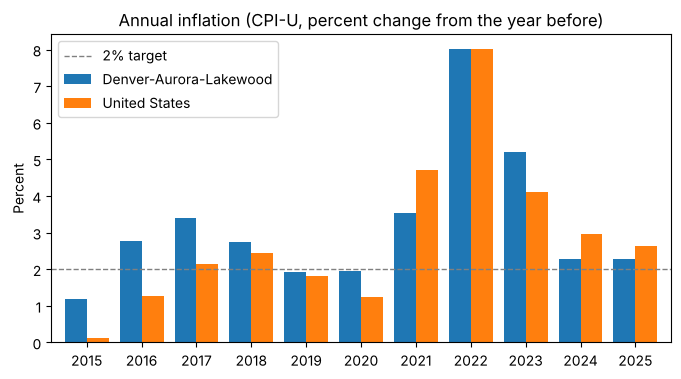

In [21]:
# Plot pairs as bars (rot=0); a dashed gray line at 2 labeled "2% target"; a title, a y label, no x label, and a legend
ax = pairs.plot.bar(figsize=(8, 4), rot=0, width=0.8)
ax.axhline(y=2, color="gray", linestyle="--", linewidth=1, label="2% target")
ax.set(title="Annual inflation (CPI-U, percent change from the year before)", ylabel="Percent", xlabel="")
ax.legend()
plt.show()

<details>
<summary>💬 Discuss</summary>

- In which years did Denver's prices rise faster than the nation's, and in which slower?
- Denver's series is annual and the nation's monthly. What would have gone wrong if we had merged the monthly series with the annual one, without `frequency="a"`?
- Housing is the largest part of the CPI. What would you ask FRED next to test whether rent explains the gap?

</details>

## Step 12 — EIA: routes that describe themselves (6 minutes)

The EIA's (U.S. Energy Information Administration's) API is a tree of **routes**, paths such as `electricity/retail-sales/` ([documentation](https://www.eia.gov/opendata/documentation.php)). Ask for a route without asking for its data, and it describes itself: at the top, the routes under it; further down, what its data can be filtered by and what it holds, as the chapter's ["Routes That Describe Themselves"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#routes-that-describe-themselves) shows. Every answer is inside the JSON's `"response"`. It's Monday's idea, *what can I ask for?*, from a different API.

In [22]:
# eia_base = "https://api.eia.gov/v2"; request f"{eia_base}/electricity/" with params={"api_key": eia_key} and HEADERS
# Print each of the JSON's ["response"]["routes"]: its "id" and its "name"
eia_base = "https://api.eia.gov/v2"
electricity = requests.get(f"{eia_base}/electricity/", params={"api_key": eia_key}, headers=HEADERS).json()["response"]
for child in electricity["routes"]:
    print(child["id"], "|", child["name"])

retail-sales | Electricity Sales to Ultimate Customers
electric-power-operational-data | Electric Power Operations (Annual and Monthly)
rto | Electric Power Operations (Daily and Hourly)
state-electricity-profiles | State Specific Data
operating-generator-capacity | Inventory of Operable Generators
facility-fuel | Electric Power Operations for Individual Power Plants (Annual and Monthly)


In [23]:
# meta: the "response" of f"{eia_base}/electricity/retail-sales/", requested the same way
# Print its "frequency" ids and its "facets" ids; then each column of its "data", with that column's "units"
meta = requests.get(f"{eia_base}/electricity/retail-sales/", params={"api_key": eia_key}, headers=HEADERS).json()["response"]
print("Frequencies:", [f["id"] for f in meta["frequency"]])
print("Facets:", [f["id"] for f in meta["facets"]])
for column, about in meta["data"].items():
    print(column, "|", about["units"])

Frequencies: ['monthly', 'quarterly', 'annual']
Facets: ['stateid', 'sectorid']
revenue | million dollars
sales | million kilowatt hours
price | cents per kilowatt-hour
customers | number of customers


<details>
<summary>💬 Discuss</summary>

- Monday, the Census Bureau's catalogs were separate files, `variables.json` and `geography.json`. Here the route describes itself. Which would you rather explore, and why?
- The chapter's tour shows the EIA's API Dashboard. Where do its menus come from?
- What does a **facet** do that a data column doesn't?

</details>

## Step 13 — Let the server filter (8 minutes)

Add `data/` to the route, and it returns rows; each parameter narrows them, as the chapter's ["Let the Server Filter"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#let-the-server-filter) shows. `data[]` names the columns, `facets[stateid][]` and `facets[sectorid][]` keep only the values you list, `start` and `end` fix the years, and `sort` orders the rows. The square brackets are part of the parameters' names ([documentation](https://www.eia.gov/opendata/documentation.php)), and `requests` encodes them for you. Ask for the average price of electricity in Colorado's homes, every year from 2001 to 2025.

In [24]:
# params: frequency="annual", data[]="price", facets[stateid][]="CO", facets[sectorid][]="RES", start="2001", end="2025"
#   and sort[0][column]="period", sort[0][direction]="asc"; with api_key=eia_key
# Request f"{eia_base}/electricity/retail-sales/data/"; prices: its "response"; print its "total"; co_price: a DataFrame of its "data"
params = {"frequency": "annual", "data[]": "price", "facets[stateid][]": "CO", "facets[sectorid][]": "RES",
          "start": "2001", "end": "2025", "sort[0][column]": "period", "sort[0][direction]": "asc",
          "api_key": eia_key}
prices = requests.get(f"{eia_base}/electricity/retail-sales/data/", params=params, headers=HEADERS).json()["response"]
print("Rows:", prices["total"])
co_price = pd.DataFrame(prices["data"])
co_price[["period", "stateid", "sectorName", "price", "price-units"]].tail(3)

Rows: 25


,period,stateid,sectorName,price,price-units
22,2023,CO,residential,14.3,cents per kilowatt-hour
23,2024,CO,residential,14.92,cents per kilowatt-hour
24,2025,CO,residential,15.69,cents per kilowatt-hour


### ⏱ Microsprint (4 minutes, alone or in pairs)

Change one facet.

**Do:** ask for the same price in another sector (`COM`, commercial, or `IND`, industrial), or for homes in another state (its two-letter code, such as `UT` or `NM`). The key asks for Colorado's commercial price.
**Share:** your sector or state, its 2025 price, and how it compares with Colorado's homes.

In [25]:
# Microsprint: set params["facets[sectorid][]"] (or params["facets[stateid][]"]) to your choice; request again
# Show the last 3 rows of period, stateid, sectorName, and price
params["facets[sectorid][]"] = "COM"
other = requests.get(f"{eia_base}/electricity/retail-sales/data/", params=params, headers=HEADERS).json()["response"]
pd.DataFrame(other["data"])[["period", "stateid", "sectorName", "price"]].tail(3)

,period,stateid,sectorName,price
22,2023,CO,commercial,11.64
23,2024,CO,commercial,11.71
24,2025,CO,commercial,12.37


<details>
<summary>💬 Discuss</summary>

- How many rows came back, out of a route that holds every state and sector by month, quarter, and year? What did filtering on the server save?
- The prices arrive as strings. Which line would fail if you tried to average them?
- Why do businesses pay less per kilowatt-hour than homes?

</details>

## Step 14 — Paging with `offset` and `length` (7 minutes)

The EIA's (U.S. Energy Information Administration's) API returns at most 5,000 rows a request. Colorado's monthly generation from every source, 2001 to 2025, is more than that. The response says how many rows match in `total`, and you ask for the next page with `offset`, the rows to skip, and `length`, the rows to return ([documentation](https://www.eia.gov/opendata/documentation.php); the chapter's ["Paging with `offset` and `length`"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html#paging-with-offset-and-length)). Ask for two pages by hand. Then read the chapter's loop, which is given, and use it. Compare it with week 10's: Wikipedia sent a `continue` token; the EIA tells you the total, and you keep count.

In [26]:
# params: frequency="monthly", data[]="generation", facets[location][]="CO", facets[sectorid][]="99", start="2001-01", end="2025-12",
#   sorted by "period" and then "fueltypeid", ascending, with api_key=eia_key, offset=0, length=5000
# gen_url: f"{eia_base}/electricity/electric-power-operational-data/data/"; request page one; print its "total" and its number of rows
params = {"frequency": "monthly", "data[]": "generation", "facets[location][]": "CO", "facets[sectorid][]": "99",
          "start": "2001-01", "end": "2025-12",
          "sort[0][column]": "period", "sort[0][direction]": "asc",
          "sort[1][column]": "fueltypeid", "sort[1][direction]": "asc",
          "api_key": eia_key, "offset": 0, "length": 5000}
gen_url = f"{eia_base}/electricity/electric-power-operational-data/data/"
page = requests.get(gen_url, params=params, headers=HEADERS).json()["response"]
print("Total:", page["total"], "| this page:", len(page["data"]))

Total: 9289 | this page: 5000


In [27]:
# Set params["offset"] to 5000; request page two; print its number of rows and its first row's "period"
params["offset"] = 5000
page = requests.get(gen_url, params=params, headers=HEADERS).json()["response"]
print("This page:", len(page["data"]), "| starts at", page["data"][0]["period"])

This page: 4289 | starts at 2015-04


In [28]:
# Given: the chapter's loop, which keeps asking until it has the total, a second apart
import time

def eia_get_all(route, params, page_size=5000):
    rows = []
    while True:
        page_params = dict(params, api_key=eia_key, offset=len(rows), length=page_size)
        page = requests.get(f"{eia_base}/{route}", params=page_params, headers=HEADERS).json()["response"]
        print(f"offset {len(rows):>5}: {len(page['data'])} rows of {page['total']}")
        rows.extend(page["data"])
        if len(rows) >= int(page["total"]) or not page["data"]:
            break
        time.sleep(1)
    return pd.DataFrame(rows)

monthly_gen = eia_get_all("electricity/electric-power-operational-data/data/", params)
print(len(monthly_gen), "rows;", monthly_gen["fueltypeid"].nunique(), "energy sources")

offset     0: 5000 rows of 9289


offset  5000: 4289 rows of 9289
9289 rows; 36 energy sources


<details>
<summary>💬 Discuss</summary>

- The loop stops when it has `total` rows. Why not stop when the response stops saying `"incomplete return"`, as the chapter explains?
- Why sort when you page? What could happen to a row between page one and page two if you didn't?
- Before writing a loop like this, what would you try first to make the answer fit in one page?

</details>

## End of Part 2

On Friday, Part 3 follows Congress.gov's links from one record to the next, joins two of the week's APIs, and ends with what we learned. It starts with its own setup step.